# Improving the 12-spin ALiBi wavefunction

This is a measured AutoDL benchmark on the **same** periodic Kagome Hamiltonian:
L=2, N=12, positive random bonds K∈[0.5,1.5], disorder ID 0, Γ=0.5, h=0.3.

The final model uses ALiBi. We keep the shared model's architecture (width 32,
two causal blocks, four heads, one static context block) and specialize its
weights to this Hamiltonian. This experiment does not establish that the
specialized checkpoint retains accuracy on other sizes or disorder samples.

Four sampled-VMC runs compare shared-checkpoint initialization against a fresh
ALiBi initialization, each with seeds 101 and 102. Each run uses 4,000 updates,
batch 512, and an Adam learning rate decaying from 0.001 to 0.0001. The
original shared model had only 200 updates per Hamiltonian context.

**Training uses sampled energy gradients, without exact ground-state labels.**
Every 200 updates we enumerate the learned distribution over 4,096 states for
validation. Checkpoints are selected by lowest enumerated variational energy;
the exact ground state is used to assess energy and observable errors. This is
a benchmark on the training Hamiltonian, not a held-out generalization test.

Accuracy targets were set before this run: energy error <10⁻⁴ per spin,
relative raw-overlap error <1%, and relative connected-susceptibility error <5%.


In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
ROOT=Path.cwd()
if not (ROOT/'code/transformer_qmc').exists():
    ROOT=ROOT.parent
RESULTS=ROOT/'data/kagome/transformer_af_alibi_l2_v1'
summary=json.loads((RESULTS/'summary.json').read_text())
selected=json.loads((RESULTS/'selected.json').read_text())
reference=json.loads((RESULTS/'exact.json').read_text())
baseline=json.loads((ROOT/'data/kagome/transformer_af_dual_v1/benchmark/small_system.json').read_text())
rows=[('Original shared ALiBi',baseline['unified']),('Earlier fixed model',baseline['fixed'])]
rows += [(r['task']['initialization']+' ALiBi, seed '+str(r['task']['seed']),r['diagnostics']) for r in summary]
table=['| Model | E/N | Energy error/spin | Raw overlap | Connected χ |', '|---|---:|---:|---:|---:|']
table.append(f"| Exact | {reference['energy']/12:.9f} | 0 | {reference['q2']:.7f} | {reference['chi_connected']:.7f} |")
for label,d in rows:
    table.append(f"| {label} | {d['energy']/12:.9f} | {(d['energy']-reference['energy'])/12:.3g} | {d['q2']:.7f} | {d['chi_connected']:.7f} |")
display(Markdown('\n'.join(table)))
display(Markdown('All values above use full enumeration of the learned state, so they have no Monte Carlo sampling error.'))


| Model | E/N | Energy error/spin | Raw overlap | Connected χ |
|---|---:|---:|---:|---:|
| Exact | -1.111914710 | 0 | 0.6818610 | 0.0652889 |
| Original shared ALiBi | -1.011455526 | 0.1 | 0.3020245 | 0.6404199 |
| Earlier fixed model | -1.111314358 | 0.0006 | 0.6883074 | 0.0621976 |
| shared ALiBi, seed 101 | -1.111904984 | 9.73e-06 | 0.6823429 | 0.0650648 |
| shared ALiBi, seed 102 | -1.111904962 | 9.75e-06 | 0.6824357 | 0.0650997 |
| fresh ALiBi, seed 101 | -1.111849271 | 6.54e-05 | 0.6815882 | 0.0653517 |
| fresh ALiBi, seed 102 | -1.111865541 | 4.92e-05 | 0.6830574 | 0.0647330 |

All values above use full enumeration of the learned state, so they have no Monte Carlo sampling error.

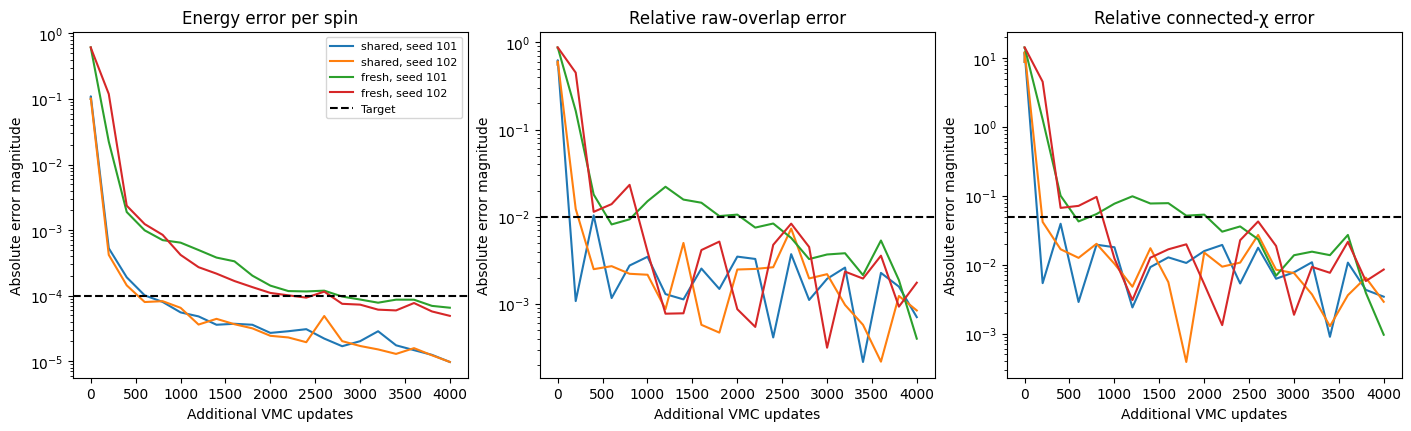

In [2]:
fig,axes=plt.subplots(1,3,figsize=(14,4.2),constrained_layout=True)
for r in summary:
    directory=RESULTS/Path(r['best_checkpoint']).parent
    trace=json.loads((directory/'validation.json').read_text())
    label=f"{r['task']['initialization']}, seed {r['task']['seed']}"
    for ax,key in zip(axes,['energy_error_per_spin','q2_relative_error','chi_connected_relative_error']):
        ax.semilogy([t['step'] for t in trace],[max(abs(t[key]),1e-12) for t in trace],label=label)
for ax,target,title in zip(axes,[1e-4,.01,.05],['Energy error per spin','Relative raw-overlap error','Relative connected-χ error']):
    ax.axhline(target,color='black',linestyle='--',label='Target')
    ax.set(xlabel='Additional VMC updates',ylabel='Absolute error magnitude',title=title)
axes[0].legend(fontsize=8)
fig.savefig(RESULTS/'alibi_l2_accuracy.png',dpi=180)
fig.savefig(RESULTS/'alibi_l2_accuracy.pdf')
plt.show()


In [3]:
d=selected['diagnostics']
display(Markdown(f"**Selected model:** {selected['name']}, step {selected['best_step']}.\n\n"
                 f"Energy error per spin: **{d['energy_error_per_spin']:.3g}**; "
                 f"raw-overlap error: **{100*d['q2_relative_error']:.3f}%**; "
                 f"connected-susceptibility error: **{100*d['chi_connected_relative_error']:.3f}%**. "
                 f"Squared overlap with the exact ground state: **{d['fidelity']:.8f}**.\n\n"
                 f"All three targets met: **{d['qualified']}**.\n\n"
                 f"Checkpoint: `{selected['best_checkpoint']}`"))


**Selected model:** alibi__L02__N012__g0p5__h0p3__dis000__init-shared__seed101, step 4000.

Energy error per spin: **9.73e-06**; raw-overlap error: **0.071%**; connected-susceptibility error: **0.343%**. Squared overlap with the exact ground state: **0.99997676**.

All three targets met: **True**.

Checkpoint: `alibi__L02__N012__g0p5__h0p3__dis000__init-shared__seed101/alibi__L02__N012__g0p5__h0p3__dis000__init-shared__seed101__best.pt`

## What this establishes

The table and traces distinguish architecture capability from the quality of
the initial mixed-context training. Compare both initializations and both seeds;
do not infer that pretraining always helps from one selected checkpoint.

The selected ALiBi state is specialized to this 12-spin Hamiltonian. Applying it
as a frozen projector guide still requires projection-time, walker-population,
and ancestry checks. Accurate larger-size or held-out-disorder performance is
a separate qualification task. The earlier fixed-position state is retained as
a benchmark, while the selected final state uses ALiBi.
